In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import pandas as pd

from cherab.core.atomic import carbon, hydrogen
from cherab.openadas import OpenADAS
from Emissivity_Profile_TCABR.Emissivity import get_emissivity
from abel_inversion.abel_inversion import onion_peeling_method

In [2]:
def Vphi_model(x_i, a, DeltaV, gama):
    """Calcula o modelo de sino da velocidade toroidal eliminando os valores imaginários e divisões por zero

    Parâmetros:
        x_i (float): Intervalos de valores de raio 
        a (float): raio maior do tokamak 
        DeltaV (float): Amplitude da velocidade 
        Gama (float):  Expoente efetivo
    Retorna:
        V_phi (arr): V_phi(x_i) simulada seguindo modelo descrito em Wesson J., Tokamaks (2004).
    """
    # Recusa valores de a negativos e iguais a 0
    if a <= 0:
        return print("Please insert the original Radius of your Tokamak")

    # Adapta o código para listas e números
    x_i = np.asarray(x_i)

    # Tratamento de possíveis valores negativos
    power = gama - 1
    base = 1 - (x_i/a)**2

    resultado = DeltaV * gama * (-2 * (x_i / a**2)) * (base**power)
    
    if power < 0:
        invalido = (base<=0)
    else:
        invalido = base<0
    
    return np.where(invalido,0.0,resultado)

def Vapp(eps, Vphi, W_ij):
    """Aplicação do modelo direto propagando a velocidade de plasma.

    Parâmetros:
        x_i (float): Valores de emissividade ao longo do raio.
        Vphi (float): Valores de velocidade toroidal ao longo do raio.
        W_ij (arr): Matriz de peso calculada utilizando o método de Onion Peeling.
    Retorna: 
        Vapp (arr): Curvas de valores de velocidade aparente.    
    """
    U = W_ij @ (eps*Vphi)
    S = W_ij @ eps
    return U/S

In [3]:
adas = OpenADAS(permit_extrapolation=True)

In [4]:
df = pd.read_csv('Data/organized_data.csv', sep = ';')

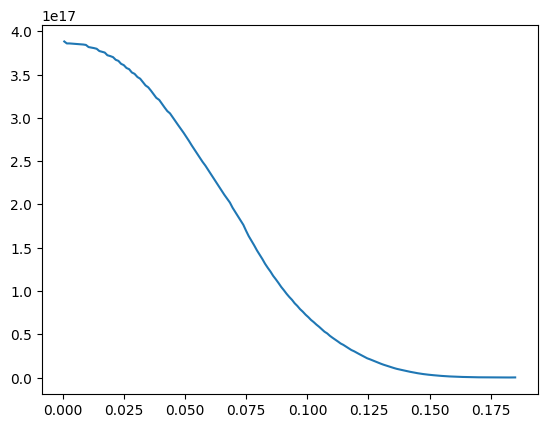

In [5]:
plt.plot(df['raio[m]'],df['emissivity[fotonsm^-3s^-2]'])

In [6]:
x = df['raio[m]'].to_numpy()
y = df['emissivity[fotonsm^-3s^-2]'].to_numpy()

In [7]:
interp = sp.interpolate.CubicSpline(x,y)

In [8]:
n_cordas = 16
a = 0.18 #m 
DeltaV = 5e6 #m/s
gama = 1.5

x_new = np.linspace(x[0],x[-1],n_cordas)
y_new = interp(x_new[:])

x_normal = x_new/x_new.max()

Vphi = Vphi_model(x_new, a, DeltaV, gama)

/tmp/ipykernel_13922/2425320194.py:23: RuntimeWarning: invalid value encountered in sqrt
  resultado = DeltaV * gama * (-2 * (x_i / a**2)) * (base**power)


/tmp/ipykernel_13922/989616191.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


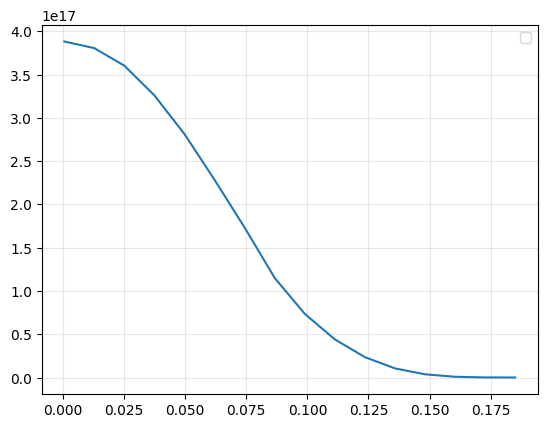

In [9]:
plt.plot(x_new,y_new)
plt.xlabel("")
plt.ylabel("")
plt.grid(True, which = "both", alpha =.3)
plt.legend()
plt.show()

In [10]:
W_ij, D_ij = onion_peeling_method(n_cordas,x_new)

In [11]:
U = W_ij @ (y_new*Vphi)
S = W_ij @ y_new

In [12]:
Vapp = U/S

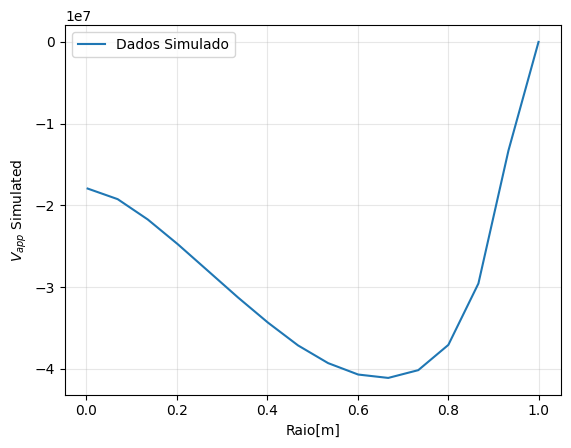

In [13]:
plt.plot(x_normal, Vapp, label = f'Dados Simulado')
plt.xlabel("Raio[m]")
plt.ylabel(r"$V_{app}$ Simulated")
plt.grid(True, which = "both", alpha =.3)
plt.legend()
plt.show()

In [14]:
## plotar a curva com ruidos
nivel = [.01,.03,.05]

Vpp_ruido = []
sigma_list = []

for i in range(len(nivel)):
    sigma = nivel[i] * np.abs(Vapp)
    sigma_list.append(sigma)
    error = np.random.normal(loc = 0.0, scale = sigma, size = n_cordas)
    Vpp_ruido.append(Vapp + error)

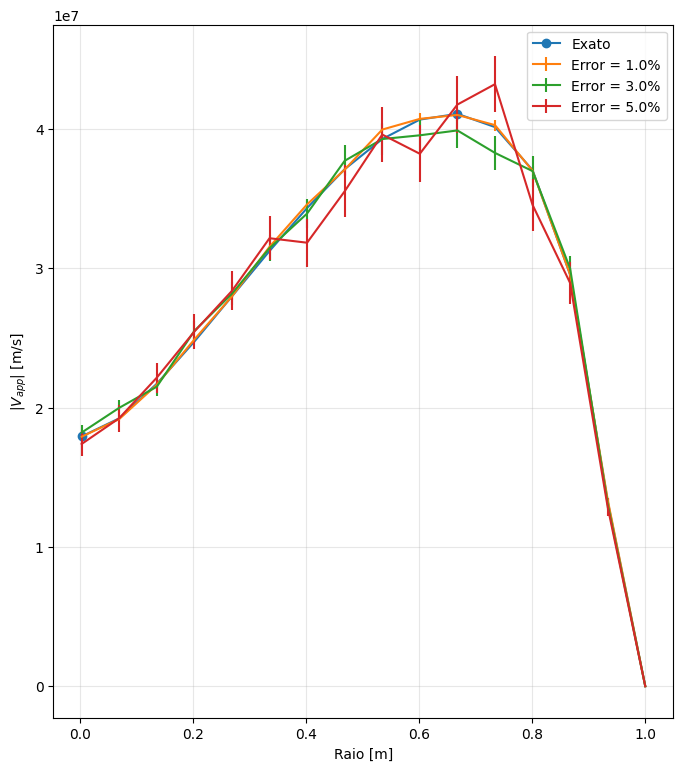

In [28]:
fig = plt.figure(figsize=(8,9))
plt.plot(x_normal, abs(Vapp), marker = "o", markevery = 10,label = f'Exato')
for i in range(len(nivel)):    
    plt.errorbar(x_normal, abs(Vpp_ruido[i]), yerr = sigma_list[i], label = f'Error = {nivel[i]*100}%')
plt.xlabel("Raio [m]")
plt.ylabel(r"$|V_{app}|$ [m/s]")
plt.grid(True, which = "both", alpha =.3)
plt.legend()
plt.savefig('Resultados/26102026/V_app.png')
plt.show()